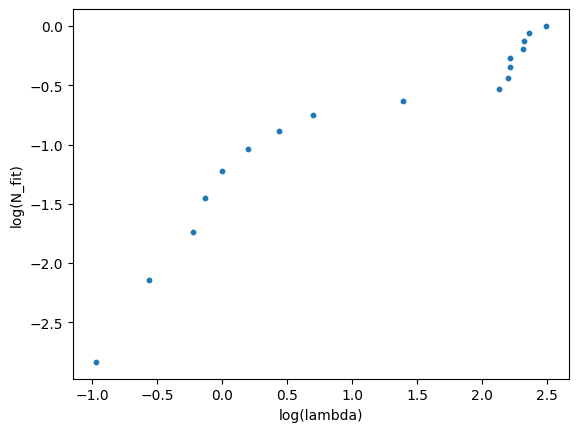

5
dimension  3.2272968025485858
0.08265510383435752 1.0053053309983535
[ 2.700615  5.535813  5.537087  7.32582   7.325824 17.161954 17.162014
 17.354378 17.614161]
9


In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
import scipy.linalg as la
from scipy.linalg import expm
import csv
import networkx as nx
from collections import defaultdict
import mpmath as mp
import sys
import ast
from sklearn.metrics.cluster import normalized_mutual_info_score

def curvature(laplacianMatrix, fullVector=False):
    # Numpy solver
    eigenvalues = np.linalg.eigvalsh(laplacianMatrix)
    eigenvalues = np.real(eigenvalues)
    eigenvalues = eigenvalues[eigenvalues > 1e-10]

    # Scipy solver
    # eigenvalues = la.eigvalsh(laplacianMatrix, lower=False)
    # eigenvalues[np.isclose(eigenvalues, 0, atol=1e-15)] = 0.0
    # eigenvalues = eigenvalues[eigenvalues > 1e-10]

    # mpmath solver (insanely slow)
    # mp.mp.dps = 15 # decimal places
    # laplacianMatrix = mp.matrix(laplacianMatrix.tolist())
    # eigenvalues, _ = mp.eigsy(laplacianMatrix)
    # eigenvalues = [ev for ev in eigenvalues if ev > mp.mpf('1e-10')]

    N = len(eigenvalues)

    round_digits = 9
    eigenvalues = np.round(eigenvalues, round_digits)
    lambda_fit = np.unique(np.sort(eigenvalues))
    N_fit = np.zeros(len(lambda_fit))

    for i in range(len(lambda_fit)):
        c = np.where(lambda_fit < lambda_fit[i])[0]
        N_fit[i] = (len(c)+1) / len(lambda_fit)

    mask = N_fit > 0
    x = np.log(lambda_fit[mask])
    y = np.log(N_fit[mask])

    # plt.scatter(lambda_fit[mask], N_fit[mask])
    plt.scatter(x, y, s=10)
    plt.xlabel("log(lambda)")
    plt.ylabel("log(N_fit)")
    plt.show()

    lowpoints = 4
    nbpoints = len(x)
    rsq = np.zeros(nbpoints - lowpoints + 1)
    slope = []

    for i in range(lowpoints, nbpoints + 1):
        fit = linregress(x[:i], y[:i])
        rsq[i - lowpoints] = fit.rvalue**2
        slope.append(2*fit.slope)
    
    best = np.argmax(rsq)
    best_n = lowpoints + best

    print(best_n)

    fit = linregress(x[:best_n], y[:best_n])

    slope = fit.slope
    dim = 2*slope
    print("dimension ", dim)

    lambda_critical = np.exp(x[best_n - 1])

    Ti = np.arange(1 / np.max(lambda_fit), 1 / np.min(lambda_fit), 0.001)
    print(1 / np.max(lambda_fit), 1 / lambda_critical)

    # max degree of whole graph
    orderinexpan = 6 #np.max(np.diag(laplacianMatrix)).astype(int)

    X = np.zeros((len(Ti), orderinexpan))

    for i in range(0, orderinexpan):
        X[:, i] = (Ti ** i) / (4 * np.pi * Ti)**(dim / 2)

    K1diag = np.zeros((laplacianMatrix.shape[0], len(Ti)))

    for i in range(len(Ti)):
        Ker1 = expm(- laplacianMatrix * Ti[i])
        K1diag[:, i] = np.diag(Ker1)

    X_pinv = np.linalg.pinv(X)

    vr = np.zeros(laplacianMatrix.shape[0])
    full_coeffs = np.zeros((laplacianMatrix.shape[0], orderinexpan))

    for j in range(laplacianMatrix.shape[0]):
        Y = K1diag[j, :]

        coeffs = X_pinv @ Y

        if fullVector:
            full_coeffs[j, :] = coeffs
        else:
            vr[j] = coeffs[1]

    resolution = 1e6
    groups = defaultdict(list)

    if fullVector:
        full_coeffs = full_coeffs[:, 1:6]

        full_coeffs[:, 0] = np.trunc(full_coeffs[:, 0] * resolution) / resolution
        full_coeffs[:, 1] = np.trunc(full_coeffs[:, 1] * 1e6) / 1e6
        full_coeffs[:, 2] = np.trunc(full_coeffs[:, 2] * 1e6) / 1e6
        full_coeffs[:, 3] = np.trunc(full_coeffs[:, 3] * 1e6) / 1e6
        full_coeffs[:, 4] = np.trunc(full_coeffs[:, 4] * 1e6) / 1e6
        # full_coeffs[:, 5] = np.trunc(full_coeffs[:, 5] * 1e6) / 1e6

        # full_coeffs = np.round(full_coeffs, decimals=9)

        print(np.unique(full_coeffs, axis=0))
        print(len(np.unique(full_coeffs, axis=0)))

        for i, row in enumerate(full_coeffs):
            groups[tuple(row)].append(i)

    else:
        vr = np.trunc(vr * resolution) / resolution

        print(np.unique(vr))
        print(len(np.unique(vr)))

        for i, value in enumerate(vr):
            groups[value].append(i)

    equivalence_classes = list(groups.values())

    return equivalence_classes, full_coeffs

def get_orbits_from_file(original_filename):
    orbits_filename = original_filename + "_orbits.txt"
    orbits = []

    with open(orbits_filename) as f:
        num_of_orbits = int(next(f).split()[0])
        for i in range(num_of_orbits):
            orbits.append(ast.literal_eval(next(f)))
    
    return orbits

# sorry for the weird function name
def turn_membership_array_into_clustering_array(array, num_of_nodes, num_of_classes):
    clustering = np.zeros(num_of_nodes)

    for i in range(len(array)):
        clustering[array[i]] = i

    return clustering

filename = "ags/ag2-08__01"
with open(filename) as f:
    num_of_nodes = int(next(f).split()[0])
    G = nx.parse_edgelist(f, nodetype=int)

G.add_nodes_from(range(num_of_nodes))
L = nx.laplacian_matrix(G, nodelist=range(num_of_nodes)).toarray()

orbits = get_orbits_from_file(filename)
orbits_clustering = turn_membership_array_into_clustering_array(orbits, num_of_nodes, len(orbits))

equivalence_classes, full_coeffs = curvature(L, fullVector=False)
equivalence_classes_clustering = turn_membership_array_into_clustering_array(equivalence_classes, num_of_nodes, len(equivalence_classes))

In [7]:
print(equivalence_classes[:10])
print(orbits[:10])

[[0], [1, 2, 3, 4, 5, 6, 7], [8, 16, 24, 32, 40, 48, 56], [9, 10, 11, 12, 13, 14, 15, 17, 18, 19, 20, 21, 22, 23, 25, 26, 27, 28, 29, 30, 31, 33, 34, 35, 36, 37, 38, 39, 41, 42, 43, 44, 45, 46, 47, 49, 50, 51, 52, 53, 54, 55, 57, 58, 59, 60, 61, 62, 63], [64], [65], [66, 67, 68, 69, 70, 71, 72, 73, 75, 76, 77, 78, 79, 80, 81, 82, 84, 85, 86, 87, 88, 89, 90, 91, 93, 94, 95, 96, 97, 98, 99, 100, 102, 103, 104, 105, 106, 107, 108, 109, 111, 112, 113, 114, 115, 116, 117, 118, 120, 121, 122, 123, 124, 125, 126, 127], [74, 83, 92, 101, 110, 119, 128], [129, 130, 131, 132, 133, 134, 135], [136]]
[[0], [1, 2, 3, 4, 5, 6, 7], [8, 16, 24, 32, 40, 48, 56], [9, 10, 11, 12, 13, 14, 15, 17, 18, 19, 20, 21, 22, 23, 25, 26, 27, 28, 29, 30, 31, 33, 34, 35, 36, 37, 38, 39, 41, 42, 43, 44, 45, 46, 47, 49, 50, 51, 52, 53, 54, 55, 57, 58, 59, 60, 61, 62, 63], [64], [65], [66, 67, 68, 69, 70, 71, 72], [73, 75, 76, 77, 78, 79, 80, 81, 82, 84, 85, 86, 87, 88, 89, 90, 91, 93, 94, 95, 96, 97, 98, 99, 100, 102, 

In [8]:
full_coeffs

array([[0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       ...,
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.]], shape=(719, 6))

In [ ]:
# Compare only
print(normalized_mutual_info_score(orbits_clustering[:137], equivalence_classes_clustering[:137]))
print(len(np.unique(equivalence_classes_clustering[:137])))
print(equivalence_classes_clustering[:137])
print(orbits_clustering[:137])
print(orbits_clustering[:137] - equivalence_classes_clustering[:137])